In [1]:
from pathlib import Path
import yaml
import pymc3 as pm
import theano.tensor as tt
from theano.compile.ops import as_op
import arviz as az
import pandas as pd
import json

from models.aux_funcs import *
import models.pymc3FoamModel as bayes_model

ROOT = Path.cwd()

The version of PyMC you are using is very outdated.

Please upgrade to the latest version of PyMC https://www.pymc.io/projects/docs/en/stable/installation.html

Also notice that PyMC3 has been renamed to PyMC.


In [2]:
# Controls

FMSURF = 2500

FG075_WEIGHT = 5.0

run_mcmc = False

MCMC_SAMPLES = 100000
MCMC_BURNIN = 5000
MCMC_NCHAINS = 4
NCORES = 4
BASE_SEED = 1
RHAT_LIMIT = 1.01

OUTPUT_DIR = ROOT / "results/sample3/"

NOISE_SIGMA_MEDIAN_SURF = 0.10
NOISE_SIGMA_MEDIAN_OIL = 0.03
NOISE_LOG_VARIANCE_STD = 1.5

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Inputs
with open("inputs/sample3_inputs.yaml", "r") as f:
    inputs = yaml.safe_load(f)
with open("inputs/sample3_experimentalData.yaml", "r") as f:
    experiments = yaml.safe_load(f)

In [5]:
inputs

{'core': {'k': 4.0384901436e-13, 'phi': 0.099, 'L': 0.245, 'D': 0.0381},
 'relPerm': {'swc': 0.36,
  'sgr': 0.0,
  'sor': 0.0,
  'nw_': 2.7,
  'ng_': 6.89,
  'no_': 1.0,
  'krw0': 0.365,
  'krg0': 0.278,
  'kro0': 1.0},
 'fluids': {'muw': 0.000603, 'mug': 1.25e-05, 'muo': 1.0, 'sigma': 1.0}}

In [6]:
fixed_rp = np.array([
    inputs["relPerm"][key]
    for key in ("nw_", "ng_", "krw0", "krg0", "swc", "sgr", "sor")
], dtype=float)
fixed_rp

array([2.7  , 6.89 , 0.365, 0.278, 0.36 , 0.   , 0.   ])

In [7]:
# Reading models
rp_module = load_module("relpermModel", "models/relativePermeabilityModels.py")
foam_module = load_module("foamModel", "models/foamModels.py")
foam_module.coreyBrooks3ph = rp_module.coreyBrooks3ph(inputs["relPerm"])

foam_names = list(bayes_model.FOAM_NAMES)
coordinate_names = list(bayes_model.COORDINATE_NAMES)
variance_names = ["variance_surf", "variance_oil"]
posterior_names = foam_names + ["sigma_surf", "sigma_oil"]
foam_names

['fmmob', 'epdry', 'fmdry', 'epsurf', 'epoil', 'fmoil', 'floil']

In [8]:
# Reading experiments
CONCENTRATIONS = (625, 1250, 2500)

# DIFFERENT SURFACTANT CONCENTRATIONS

scans = {}
velocity_by_concentration = {}
frames = []
for concentration in CONCENTRATIONS:
    experiment = experiments[f"FQS_{concentration}mgL"]
    scan_all = np.array(experiment["data"], dtype=float)
    scans[concentration] = scan_all

    velocity = float(experiment["ut"]) * 0.3048 / 86400 # convert to m/s
    velocity_by_concentration[concentration] = velocity
    frames.append(pd.DataFrame({
        "experiment": f"{concentration} mg/L", "Cs_mg_L": concentration,
        "fg": scan_all[:, 0], "muApp_cP": scan_all[:, 1], "ut": velocity,
    }))
surf_observations = pd.concat(frames, ignore_index=True)

# separating data
fg_obs = surf_observations["fg"].to_numpy()
mu_obs = surf_observations["muApp_cP"].to_numpy()
cs_obs = surf_observations["Cs_mg_L"].to_numpy(dtype=float)
ut_obs = surf_observations["ut"].to_numpy()
is_foam = np.ones(len(fg_obs), dtype=bool)
so_viscosity_obs = np.zeros_like(fg_obs, dtype=float)
surf_observations["So"] = so_viscosity_obs

# OIL OBSERVATION (foil)
oil_observations = pd.DataFrame(
    experiments["oil_observations"]["data"],
    columns=["So", "F2"]
)
so_obs = oil_observations["So"].to_numpy(dtype=float)
f2_obs = oil_observations["F2"].to_numpy(dtype=float)

# wheights and scale
point_weights = np.where(np.isclose(fg_obs, 0.75), FG075_WEIGHT, 1.0)
mu_scale, f2_scale = float(mu_obs.max()), float(f2_obs.max())

# MCMC inputs
fixed_relperm = deepcopy(inputs["relPerm"])

viscosity_parameters = dict(
    relPerm=deepcopy(fixed_relperm), muw=float(inputs["fluids"]["muw"]),
    mug=float(inputs["fluids"]["mug"]), fmsurf=FMSURF, So_viscosity=0.,
    fg=fg_obs.tolist(), Cs_mg_L=cs_obs.tolist(),
    weights=(1.0*point_weights).tolist(), mu_scale=mu_scale,
)
oil_parameters = dict(So=so_obs.tolist(), weight=1.0, f2_scale=f2_scale)

In [9]:
display(surf_observations)
display(oil_observations)
print(f"mu scale: {mu_scale:.2f}, f2 scale: {f2_scale:.2f}")

,experiment,Cs_mg_L,fg,muApp_cP,ut,So
0,625 mg/L,625,0.25,50.42,0.000007,0.0
1,625 mg/L,625,0.50,164.64,0.000007,0.0
2,625 mg/L,625,0.70,253.69,0.000007,0.0
3,625 mg/L,625,0.75,267.24,0.000007,0.0
4,625 mg/L,625,0.85,214.97,0.000007,0.0
5,625 mg/L,625,0.90,193.68,0.000007,0.0
6,625 mg/L,625,1.00,48.49,0.000007,0.0
7,1250 mg/L,1250,0.25,414.36,0.000007,0.0
8,1250 mg/L,1250,0.50,789.92,0.000007,0.0
9,1250 mg/L,1250,0.70,1012.54,0.000007,0.0


,So,F2
0,0.0667,1.0000
1,0.2191,0.8904
2,0.2724,0.5469
3,0.3115,0.3530
4,0.3541,0.1749


mu scale: 2079.19, f2 scale: 1.00


# Priors

Os priors são independentes nas coordenadas

$$x_M=(\log \textrm{fmmob},\log \textrm{epdry}, \textrm{fmdry},\log \textrm{epsurf},\log \textrm{epoil}, \textrm{floil}, q_{\textrm{oil}}).$$

Cada coordenada recebe uma distribuição uniforme nos limites configurados. Isso induz **priors log-uniformes** para `fmmob`, `epdry`, `epsurf` e `epoil`, e um prior uniforme físico para `fmdry`.

$$fmoil=floil+(1-floil)q_{oil},\qquad 0\le floil<fmoil\le1.$$

Os priors de floil e qoil induzem um prior conjunto para os dois limiares; fmoil e floil não recebem uniformes físicas independentes. Priors muito amplos podem dificultar a mistura e influenciar parâmetros pouco identificados; os histogramas comparam prior e posterior.

Assumimos erros Gaussianos independentes para os dados de surfactante e óleo. As duas variâncias **são desconhecidas e inferidas**, com $\log v_b\sim\mathcal N(\log s_b^2,\tau^2)$, em que $s_b$ e $\tau$ são configuráveis. São hipóteses de discrepância total (erro de medida e inadequação do modelo), não desvios padrão medidos. No PyMC3 usamos `pm.Lognormal` para cada variância e passamos sua raiz quadrada como `sigma` de `pm.Normal`.


In [10]:
# Prior bounds

SAT_EPS = 1e-6

bounds = {
    "fmmob": (10, 1e7),
    "epdry": (10, 1e4),
    "fmdry": (inputs["relPerm"]["swc"], 1 - inputs["relPerm"]["swc"]),
    "epsurf": (1e-3, 10),
    "epoil": (1e-3, 10),
    "floil": (0, 1-SAT_EPS),
    "qoil": [SAT_EPS, 1.]
}

rows = []
for name in bounds.keys():
    lo, hi = map(float, bounds[name])
    if name in ["fmmob", "epdry", "epsurf", "epoil"]:
        lo, hi = np.log(lo), np.log(hi)
    rows.append([lo, hi])
prior_bounds = np.array(rows, dtype=float)
noise_sigma_medians = np.array([NOISE_SIGMA_MEDIAN_SURF, NOISE_SIGMA_MEDIAN_OIL], dtype=float)
noise_log_variance_mu = np.log(noise_sigma_medians**2)
prior_table = pd.DataFrame(prior_bounds, index=coordinate_names, columns=["lower", "upper"])
display(prior_table)
display(pd.DataFrame({"variance": variance_names,
    "prior_median_sigma_normalized": [NOISE_SIGMA_MEDIAN_SURF, NOISE_SIGMA_MEDIAN_OIL],
    "prior_log_variance_std": NOISE_LOG_VARIANCE_STD}))

# data for pymc3 model
transformed_mu_obs = np.sqrt(point_weights)*mu_obs/mu_scale
transformed_f2_obs = np.sqrt(1.0)*f2_obs/f2_scale

,lower,upper
log_fmmob,2.302585,16.118096
log_epdry,2.302585,9.210340
fmdry,0.360000,0.640000
log_epsurf,-6.907755,2.302585
log_epoil,-6.907755,2.302585
floil,0.000000,0.999999
qoil,0.000001,1.000000


,variance,prior_median_sigma_normalized,prior_log_variance_std
0,variance_surf,0.10,1.5
1,variance_oil,0.03,1.5


As sete coordenadas recebem `pm.Uniform`. Transformações determinísticas recuperam os parâmetros físicos e impõem `floil < fmoil`. As variâncias recebem `pm.Lognormal`, e cada bloco de dados recebe uma verossimilhança `pm.Normal`.

In [11]:
# run MCMC# Construção Theano 

if run_mcmc:
    @as_op(itypes=[tt.dvector], otypes=[tt.dvector])
    def th_viscosity_model(x):
        return np.ascontiguousarray(
            bayes_model.viscosity_model(x, viscosity_parameters)[0], dtype=np.float64)

    @as_op(itypes=[tt.dvector], otypes=[tt.dvector])
    def th_oil_model(x):
        return np.ascontiguousarray(
            bayes_model.oil_model(x, oil_parameters)[0], dtype=np.float64)

    basic_model = pm.Model()
    with basic_model:
        coordinate_rvs = [pm.Uniform(name, lower=float(bounds[0]), upper=float(bounds[1]))
                          for name, bounds in zip(coordinate_names, prior_bounds)]
        x = tt.stack(coordinate_rvs)
        for name, index in [("fmmob", 0), ("epdry", 1), ("epsurf", 3), ("epoil", 4)]:
            pm.Deterministic(name, tt.exp(x[index]))
        # fmdry e floil já são variáveis físicas entre as coordenadas Uniform.
        pm.Deterministic("fmoil", x[5] + (1-x[5])*x[6])
        variance_surf = pm.Lognormal("variance_surf", mu=float(noise_log_variance_mu[0]),
                                     sigma=NOISE_LOG_VARIANCE_STD)
        variance_oil = pm.Lognormal("variance_oil", mu=float(noise_log_variance_mu[1]),
                                    sigma=NOISE_LOG_VARIANCE_STD)
        sigma_surf = pm.Deterministic("sigma_surf", tt.sqrt(variance_surf))
        sigma_oil = pm.Deterministic("sigma_oil", tt.sqrt(variance_oil))
        pm.Normal("Y_viscosity", mu=th_viscosity_model(x[:4]), sigma=sigma_surf,
                  observed=transformed_mu_obs)
        pm.Normal("Y_F2", mu=th_oil_model(x[4:]), sigma=sigma_oil,
                  observed=transformed_f2_obs)

    print("Log-probabilidade inicial por variável:")
    display(basic_model.check_test_point())
else:
    print("run_mcmc=False: a construção do modelo Theano é dispensada; serão lidas as cadeias salvas.")


run_mcmc=False: a construção do modelo Theano é dispensada; serão lidas as cadeias salvas.


In [12]:
# run MCMC sampling

expected_names = coordinate_names + variance_names
chains_path = OUTPUT_DIR / "mcmc_chains.npz"

if run_mcmc:
    rng = np.random.default_rng(BASE_SEED)
    initial_coords = rng.uniform(*prior_bounds.T, size=(MCMC_NCHAINS, len(coordinate_names)))
    initial_variances = rng.lognormal(noise_log_variance_mu, NOISE_LOG_VARIANCE_STD,
                                      size=(MCMC_NCHAINS, len(variance_names)))
    initial_points = [dict(zip(expected_names, np.r_[coords, variances]))
                      for coords, variances in zip(initial_coords, initial_variances)]

    with basic_model:
        trace = pm.sample(
            draws=MCMC_SAMPLES, tune=MCMC_BURNIN, chains=MCMC_NCHAINS,
            cores=min(NCORES, MCMC_NCHAINS), step=pm.Slice(),
            start=initial_points, random_seed=BASE_SEED,
            return_inferencedata=False, discard_tuned_samples=False,
            compute_convergence_checks=False)

    raw_chains = np.stack([
        np.stack(trace.get_values(name, combine=False, squeeze=False), axis=1)
        for name in expected_names], axis=1)
    np.savez(chains_path, raw_chains=raw_chains, names=expected_names, burnin=MCMC_BURNIN)
else:
    with np.load(chains_path, allow_pickle=False) as saved:
        if saved["names"].tolist() != expected_names:
            raise ValueError("Os nomes ou a ordem dos parâmetros salvos são incompatíveis.")
        raw_chains = saved["raw_chains"]
        MCMC_BURNIN = int(saved["burnin"])
    MCMC_NCHAINS = raw_chains.shape[2]
    MCMC_SAMPLES = raw_chains.shape[0] - MCMC_BURNIN

print(f"{MCMC_NCHAINS} cadeias: {MCMC_BURNIN} tuning + {MCMC_SAMPLES} amostras. Arquivo: {chains_path}")


4 cadeias: 5000 tuning + 100000 amostras. Arquivo: /home/anderson/inverseFoam/experiments/Vieira2024_v2/results/sample3/mcmc_chains.npz


In [13]:
# Posterior física após burn-in

raw_posterior = np.moveaxis(raw_chains[MCMC_BURNIN:], 2, 0)
physical_posterior = np.concatenate([
    bayes_model.decode_parameters(raw_posterior[..., :7]),
    np.sqrt(raw_posterior[..., 7:])], axis=-1)
idata = az.from_dict(posterior={
    name: physical_posterior[..., i] for i, name in enumerate(posterior_names)})
idata.to_netcdf(OUTPUT_DIR / "mcmc_posterior.nc")

# Convergência pelo R-hat.
diagnostics = az.rhat(idata, method="rank").to_array().to_series().rename("r_hat").to_frame()
diagnostics["converged"] = np.isfinite(diagnostics["r_hat"]) & (diagnostics["r_hat"] < RHAT_LIMIT)
posterior_df = pd.DataFrame(physical_posterior.reshape(-1, len(posterior_names)), columns=posterior_names)
statistics = posterior_df.describe(percentiles=[.025, .5, .975]).T.rename(
    columns={"2.5%": "q025", "50%": "median", "97.5%": "q975"}).join(diagnostics)
statistics.to_csv(OUTPUT_DIR / "mcmc_posterior_statistics.csv", index_label="parameter")
posterior_median = statistics.loc[foam_names, "median"]
posterior_median.to_csv(OUTPUT_DIR / "mcmc_median_parameters.csv", index_label="parameter")
print(f"Burn-in: {MCMC_BURNIN}; amostras posteriores: {len(posterior_df)}")
print(f"Todos os parâmetros com R-hat < {RHAT_LIMIT}:", bool(diagnostics["converged"].all()))
display(statistics)


Burn-in: 5000; amostras posteriores: 400000
Todos os parâmetros com R-hat < 1.01: True


,count,mean,std,min,q025,median,q975,max,r_hat,converged
fmmob,400000.0,58539.157333,7741.446702,36508.514887,45535.761354,57760.430411,75956.419253,149875.325503,1.000108,True
epdry,400000.0,192.705577,490.881032,13.386779,59.230440,115.992044,679.944759,9992.362803,1.000044,True
fmdry,400000.0,0.376837,0.004262,0.360003,0.366356,0.377386,0.383826,0.410518,1.000094,True
epsurf,400000.0,1.536206,0.123758,0.844547,1.301820,1.532568,1.792339,2.560897,1.000044,True
epoil,400000.0,2.457887,1.296200,0.313101,1.312271,1.969063,6.584522,9.995777,1.001487,True
fmoil,400000.0,0.508482,0.119482,0.315539,0.405238,0.462437,0.893893,0.999993,1.001438,True
floil,400000.0,0.204340,0.004470,0.032554,0.196135,0.204304,0.211736,0.261223,1.000519,True
sigma_surf,400000.0,0.085640,0.015782,0.042910,0.061293,0.083443,0.122762,0.229798,1.000002,True
sigma_oil,400000.0,0.016637,0.011989,0.001574,0.004189,0.013428,0.047963,0.238651,1.000910,True


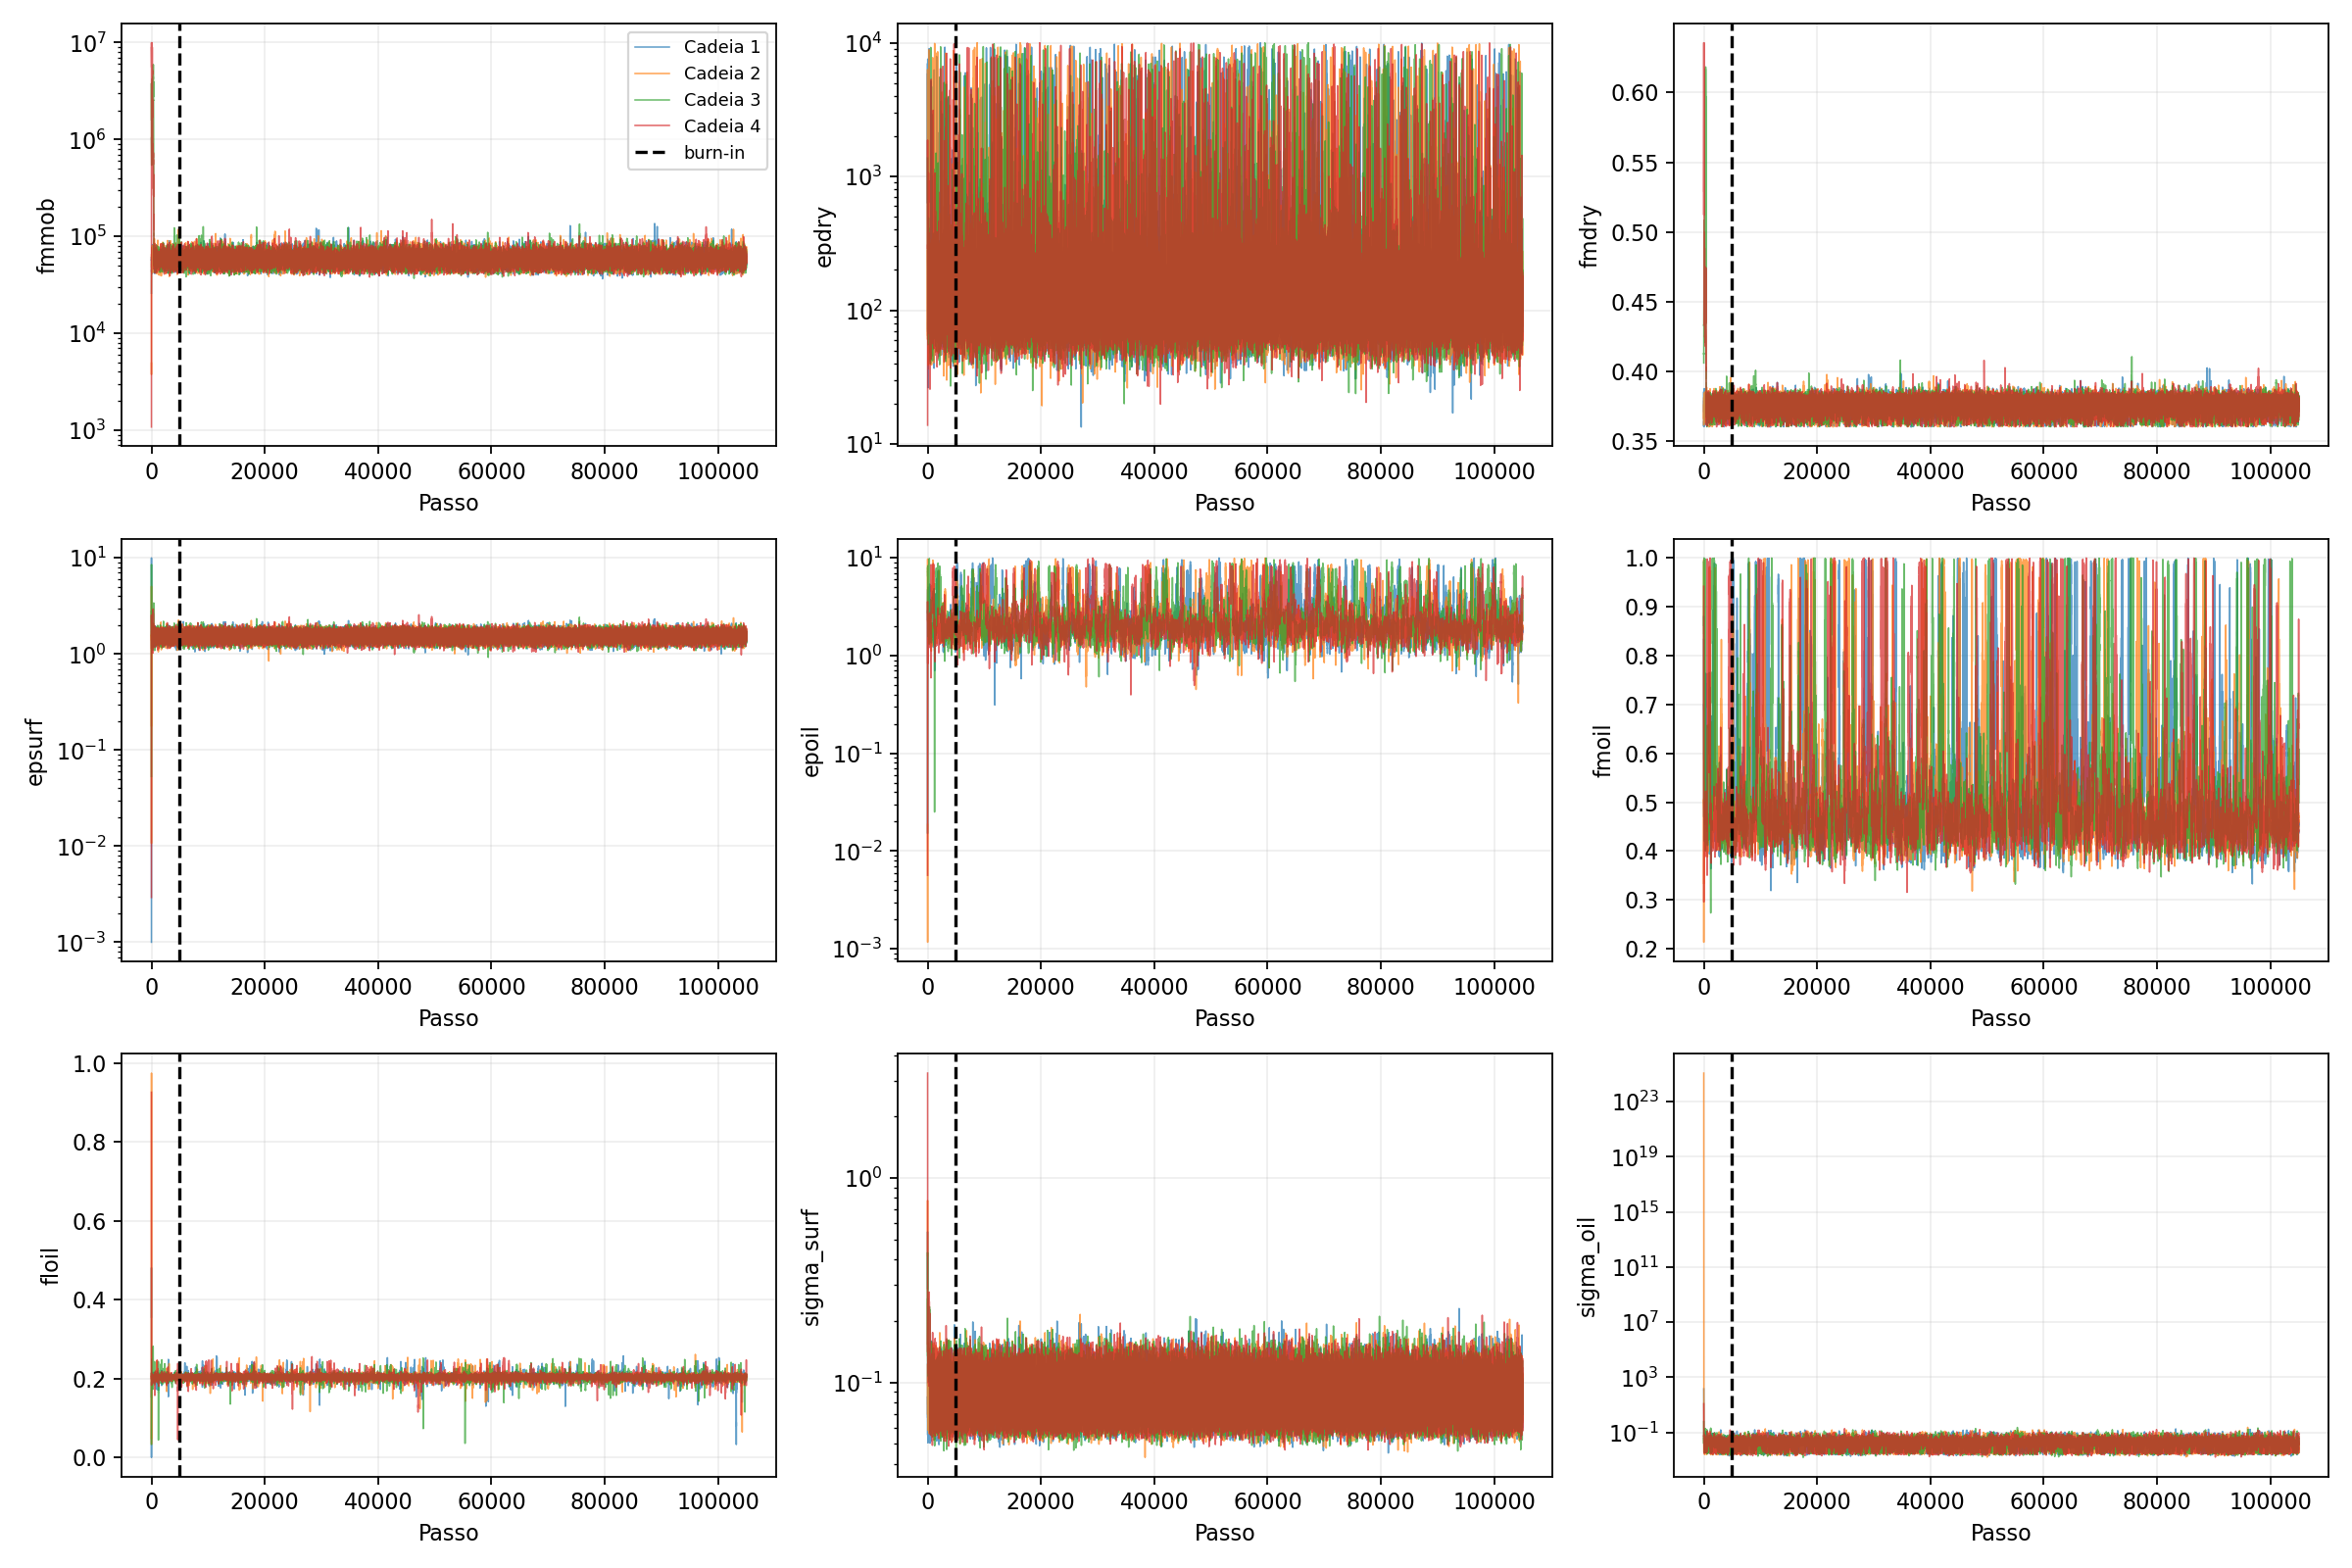

In [14]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.switch_backend("Agg")

raw = np.moveaxis(raw_chains, 1, -1)
raw_physical = np.concatenate([
    bayes_model.decode_parameters(raw[..., :7]), np.sqrt(raw[..., 7:])], axis=-1)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for i, (ax, name) in enumerate(zip(axes.flat, posterior_names)):
    ax.plot(raw_physical[:, :, i], alpha=.7, lw=.7)
    ax.axvline(MCMC_BURNIN, color="black", ls="--")
    if name in {"fmmob", "epdry", "epsurf", "epoil", "sigma_surf", "sigma_oil"}:
        ax.set_yscale("log")
    ax.set(xlabel="Passo", ylabel=name)
    ax.grid(alpha=.2)
axes.flat[0].legend([f"Cadeia {i+1}" for i in range(raw_chains.shape[2])] + ["burn-in"], fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mcmc_traces.png", dpi=160)
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR / "mcmc_traces.png")))


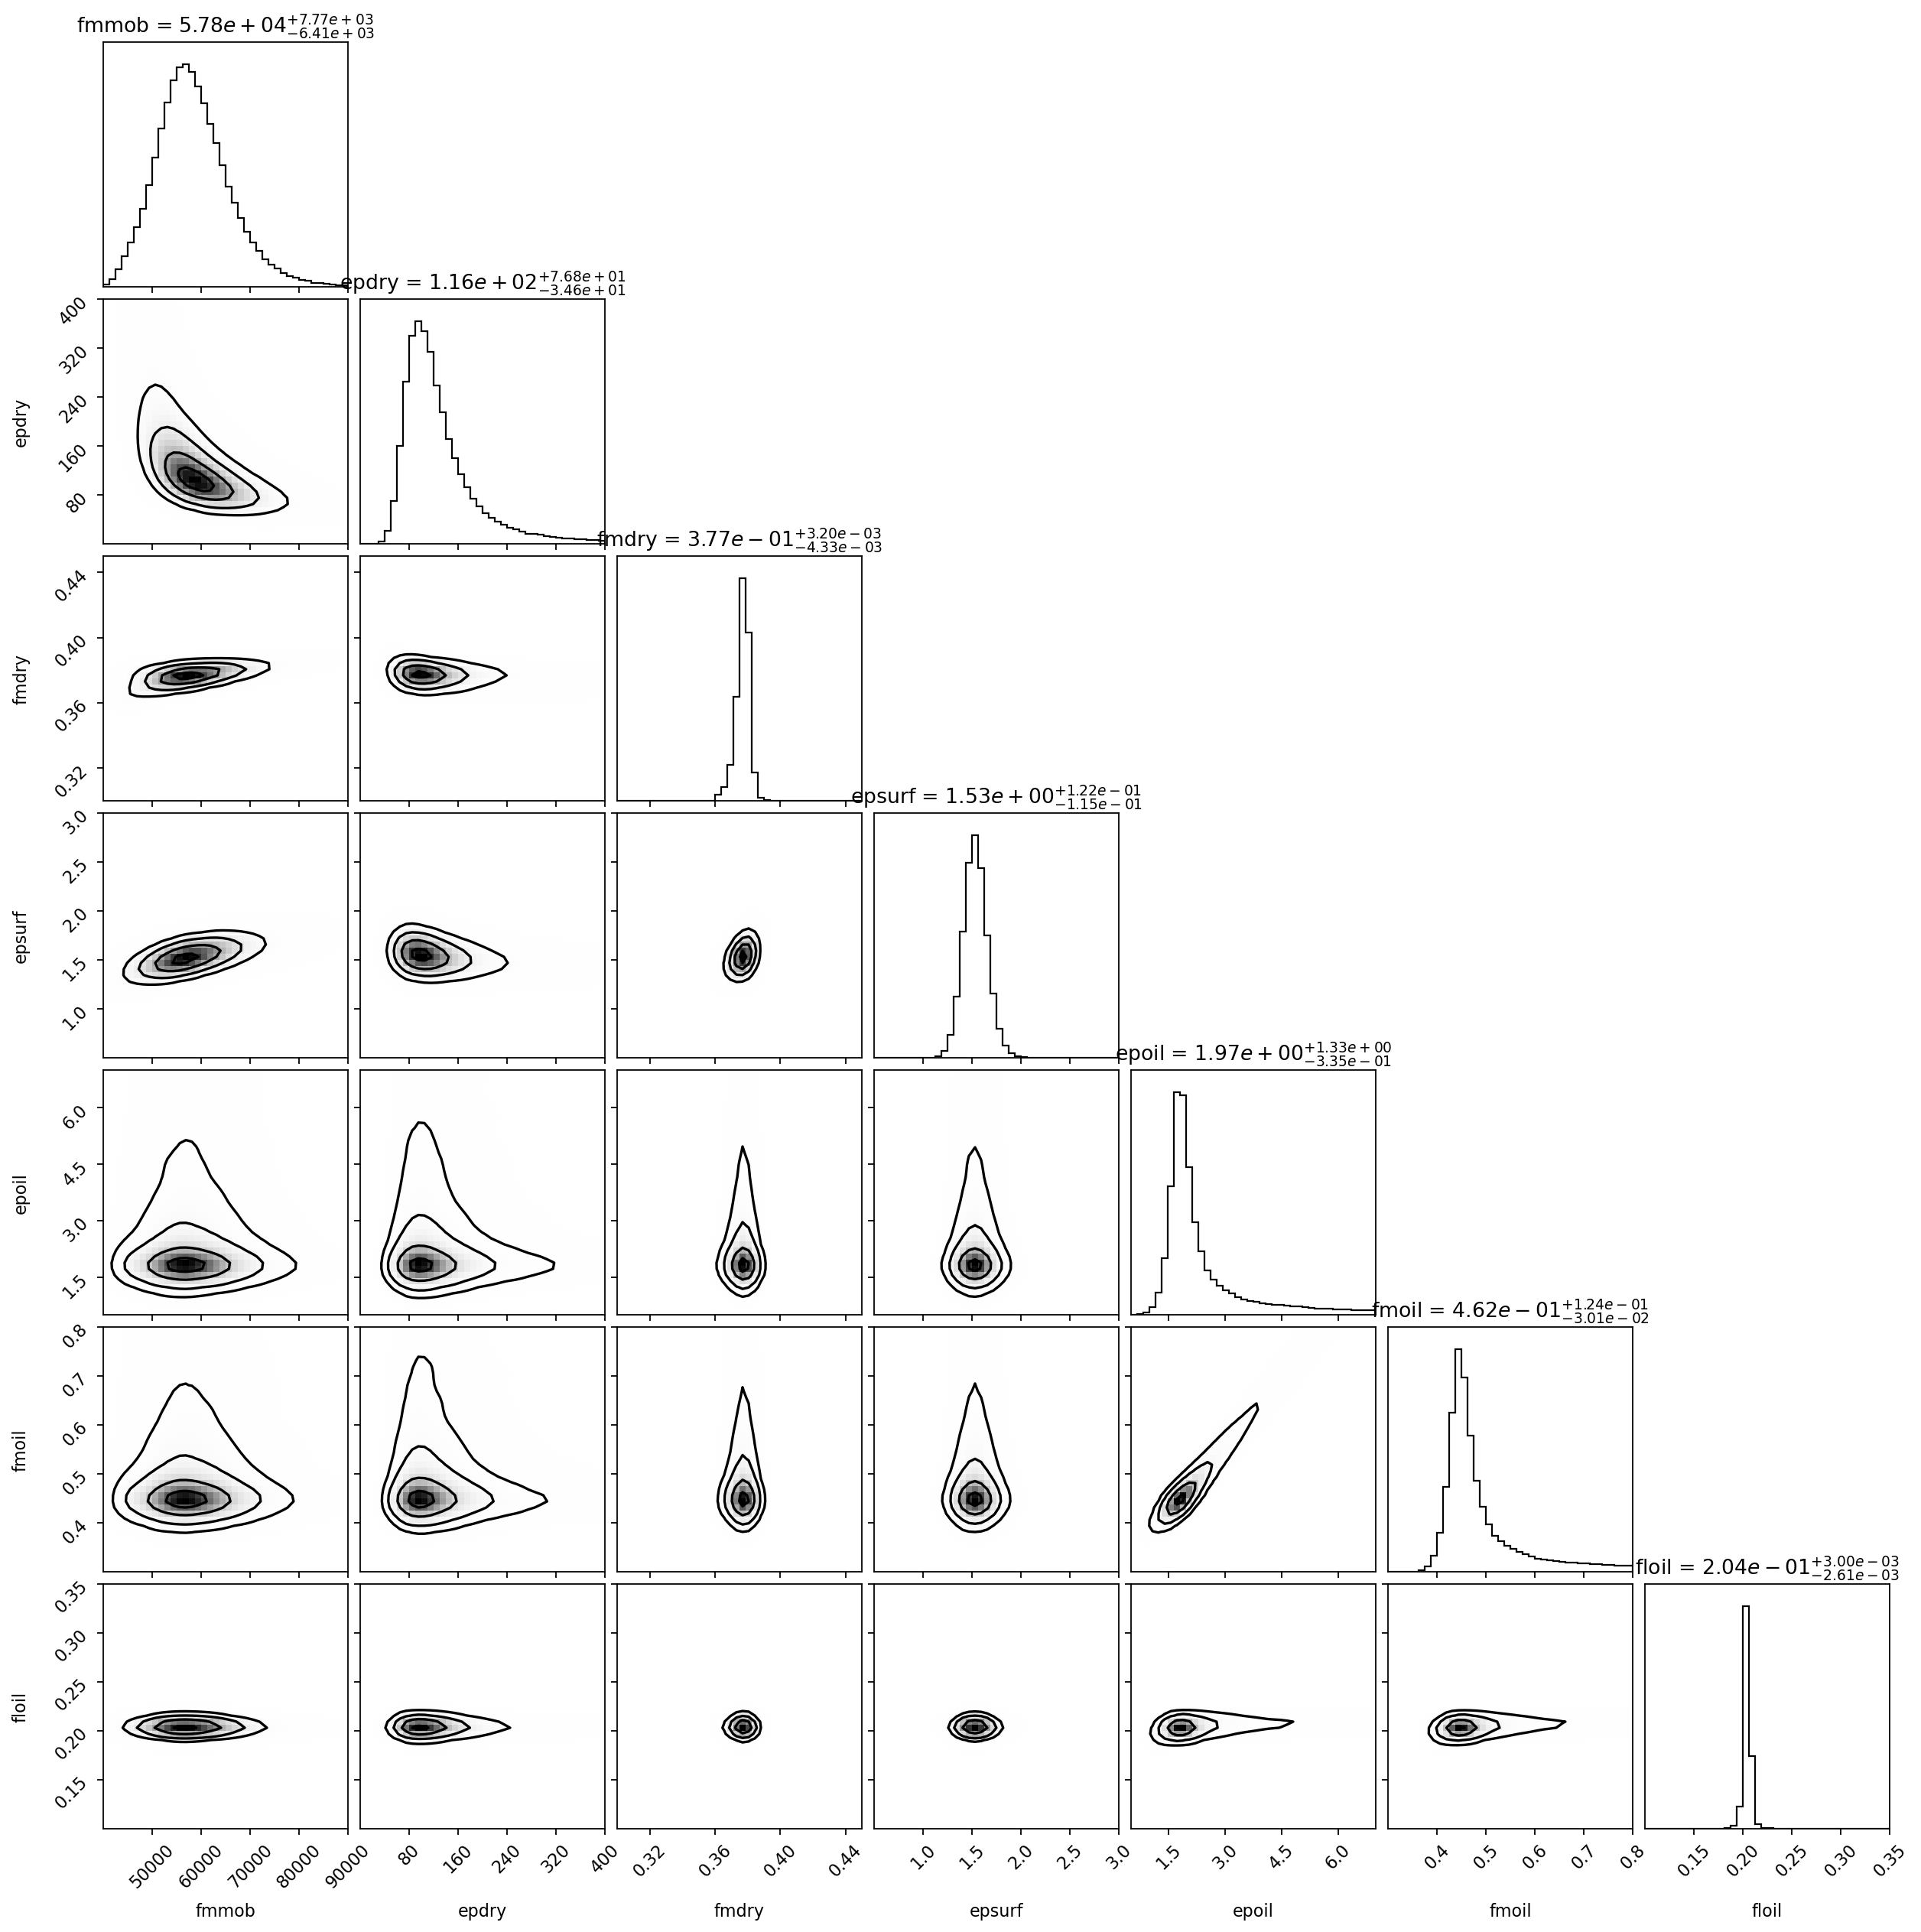

In [15]:
import corner
import numpy as np

# Limites manuais por parâmetro para evitar cortes em eixos muito apertados
parameter_limits = {
    "fmmob": (40000, 90000),
    "epdry": (0, 400),
    "fmdry": (0.3, 0.45),
    "epsurf": (0.5, 3),
    "epoil": (0.5, 7),
    "floil": (0.1, 0.35),
    "fmoil": (0.3, 0.8),
}

axis_ranges = []
for name in foam_names:
    if name in parameter_limits:
        xmin, xmax = parameter_limits[name]
        axis_ranges.append((float(xmin), float(xmax)))
    else:
        q_lo, q_hi = np.quantile(posterior_df[name].to_numpy(), [0.01, 0.99])
        axis_ranges.append((float(q_lo), float(q_hi)))

fig = corner.corner(
    posterior_df[foam_names].to_numpy(),
    labels=foam_names,
    bins=40,
    range=axis_ranges,
    show_titles=True,
    title_fmt=".2e",
    plot_datapoints=False,
    smooth=1,
)
fig.savefig(OUTPUT_DIR / "mcmc_corner.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "mcmc_corner.png", dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR / "mcmc_corner.png")))